# 🎯 Asteria: Astronomical Source Extraction & Instance Deblending with Center Offset Voting

This tutorial demonstrates Asteria's **Center Offset Voting UNet++**, featuring:
1. **Nested Dense Skip Connections (`UNetPlusPlusCenterOffset`)**: Capturing high-resolution morphological details and faint diffuse halos.
2. **Recurrent Criss-Cross Attention (RCCA)**: Multi-pass all-to-all global spatial connectivity with O(HW(H+W)) complexity, connecting extended diffraction spikes (200-500+ px) to central cores.
3. **Multi-Task Decoupled Prediction Heads**:
   - **Semantic Foreground Probability ($P_{fg}$)**: Isolating source flux from sky background.
   - **Centroid Keypoint Heatmap ($P_{ctr}$)**: Identifying Gaussian object center peaks via penalty-reduced focal priors.
   - **Dense 2D Offset Vector Field ($\Delta y, \Delta x$)**: Displacement vectors pointing each foreground pixel toward its object centroid.
4. **Colinear Ray-Aligned Offset Clustering**: Eliminating classical watershed bridge artifacts and cleanly separating intersecting galaxy disks and diffraction spikes.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import torch

import asteria
from asteria.inference.center_offset import (
    CenterOffsetSegmentor,
    extract_center_peaks,
    deblend_center_offset,
)
from asteria.visualization.plot import (
    plot_center_offset_multipanel,
    plot_center_offset_segmentation,
    plot_instance_overlay,
)
from asteria.stretch.leakysb import stretch_image

print(f"Asteria Version: {asteria.__version__}")
print(f"PyTorch Device Available: {asteria.get_optimal_device()}")

Asteria Version: 0.1.0
PyTorch Device Available: mps


---
## 1. Ingesting Astronomical Exposures

We load a simulated Nancy Grace Roman Space Telescope Wide Field Instrument (WFI) exposure (`demo_asteria_field.fits`). Asteria natively ingests FITS (`.fits`, `.fits.gz`), Roman ASDF (`.asdf`), and raw NumPy arrays.

In [2]:
scene_path = Path("demo_asteria_field.fits")
astro = asteria.load_image(scene_path)

print(f"Loaded astronomical image: {astro.data.shape} px ({astro.file_type.upper()})")
print(f"Flux dynamic range: [{astro.data.min():.4f}, {astro.data.max():.4f}] {astro.unit}")
print(f"Photometric Zero Point: {astro.zero_point}")

Loaded astronomical image: (256, 256) px (FITS)
Flux dynamic range: [0.0219, 1463.5889] DN/s
Photometric Zero Point: 31.4


# Or load another image

In [3]:
import roman_datamodels as rdm

path = '/Users/pmsanch1/storage/ROMAN/comissioning/PID1083/detectors/r0108301001001001001_0001_wfi07_f146_cal.asdf'
with rdm.open(path) as file:
    phot = file.meta
    sci_data = np.array(file.data)

norm = phot['photometry']['conversion_megajanskys']
image_data = (sci_data-np.nanmedian(sci_data)) * norm


---
## 2. Photometric Preconditioning: LeakySB Stretch

Astronomical scenes span over 5 orders of magnitude in dynamic range. Standard linear scaling clips faint diffuse emission, while logarithmic/asinh scaling can blow out bright stellar cores. **LeakySB** (Leaky Surface Brightness) preserves faint galaxy wings ($m \sim 28\text{--}30$) while maintaining sensitivity across bright cores.

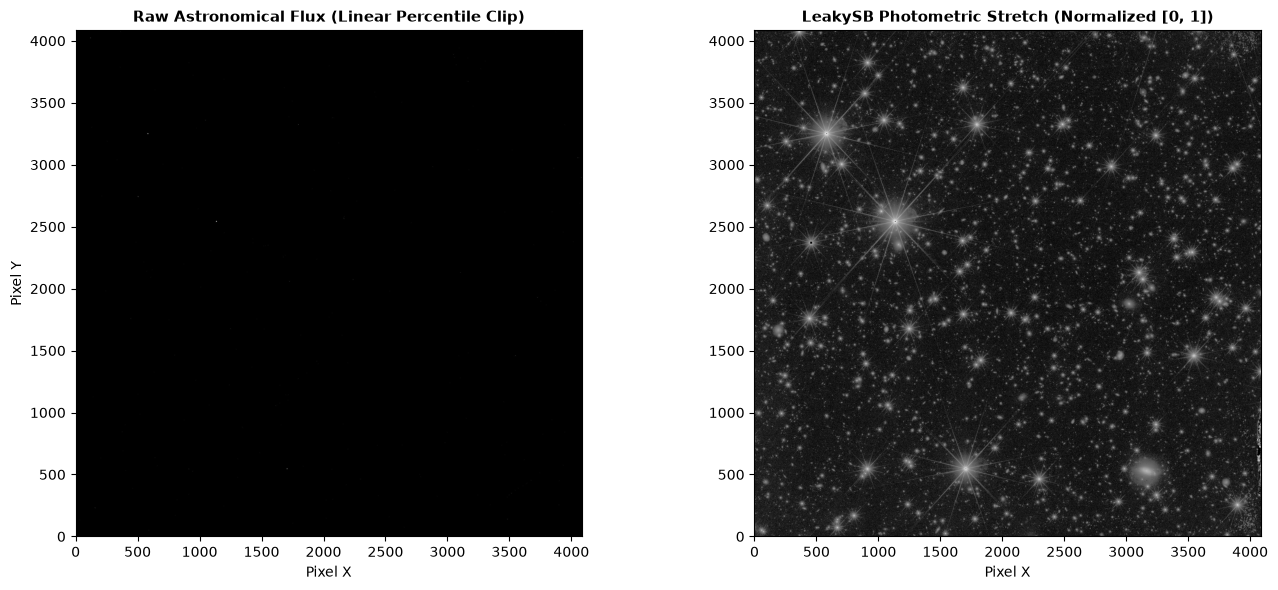

In [4]:
stretched = stretch_image(
    image_data,
    stretch_type="leakysb",
    zero_points=20.472,
    pixel_scale=1,
    mmin=13.0,
    mmax=30.0,
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(image_data, cmap="gray", origin="lower", vmin=np.percentile(image_data, 1), vmax=np.percentile(image_data, 99))
axes[0].set_title("Raw Astronomical Flux (Linear Percentile Clip)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Pixel X")
axes[0].set_ylabel("Pixel Y")

axes[1].imshow(stretched, cmap="gray", origin="lower")
axes[1].set_title("LeakySB Photometric Stretch (Normalized [0, 1])", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Pixel X")
plt.tight_layout()
plt.show()

---
## 3. Loading the UNet++ Center Offset Model

We instantiate the `CenterOffsetSegmentor` using `asteria.load_center_offset()`. The engine automatically resolves the optimal hardware accelerator (CUDA -> Apple Silicon MPS -> multi-core CPU).

In [5]:
# Load the Center Offset segmentor (or initialize with fine-tuned checkpoint path)
# segmentor = asteria.load_center_offset("latest", features=(16, 32, 64, 128, 256), use_cca=True)
segmentor = asteria.load_center_offset("/Users/pmsanch1/Documents/Research/Projects/Roman/Asteria/segment_v1/center_offset_best.pt", features=(16, 32, 64, 128, 256), use_cca=True)

total_params = sum(p.numel() for p in segmentor.model.parameters())
print(f"Inference Engine: {type(segmentor).__name__}")
print(f"Model Architecture: {type(segmentor.model).__name__}")
print(f"Recurrent Criss-Cross Attention (RCCA): {segmentor.model.use_cca}")
print(f"Total Model Parameters: {total_params:,}")
print(f"Active Accelerator: {segmentor.device}")

Inference Engine: CenterOffsetSegmentor
Model Architecture: UNetPlusPlusCenterOffset
Recurrent Criss-Cross Attention (RCCA): True
Total Model Parameters: 9,598,182
Active Accelerator: mps


---
## 4. Multi-Task Model Inference (`predict`)

Executing `segmentor.predict()` produces three complementary spatial predictions:
- `pred_semantic`: Binary foreground probability map $P_{fg} \in [0, 1]$
- `pred_center`: Centroid keypoint heatmap $P_{ctr} \in [0, 1]$
- `pred_offset`: Dense displacement vector field $(\Delta y, \Delta x)$ of shape `(2, H, W)`

In [6]:
pred_semantic, pred_center, pred_offset, stretched_img = segmentor.predict(
    image=image_data,
    stretch_type="leakysb",
    verbose=True,
    zero_points=20.472,
    pixel_scale=1,
    mmin=13.0,
    mmax=30.0,
)

print(f"Semantic Map Shape:     {pred_semantic.shape} (Range: [{pred_semantic.min():.3f}, {pred_semantic.max():.3f}])")
print(f"Center Heatmap Shape:   {pred_center.shape} (Range: [{pred_center.min():.3f}, {pred_center.max():.3f}])")
print(f"Offset Field Shape:     {pred_offset.shape} [dy, dx]")

Semantic Map Shape:     (4088, 4088) (Range: [0.000, 1.000])
Center Heatmap Shape:   (4088, 4088) (Range: [0.004, 1.000])
Offset Field Shape:     (2, 4088, 4088) [dy, dx]


---
## 5. Visualizing the Multi-Task Diagnostic Panel

Asteria provides `plot_center_offset_multipanel()` to render the input image alongside the three predicted heads, including a vector displacement quiver field pointing directly toward source centroids.

Extracted 15217 candidate center centroid peaks via peak NMS


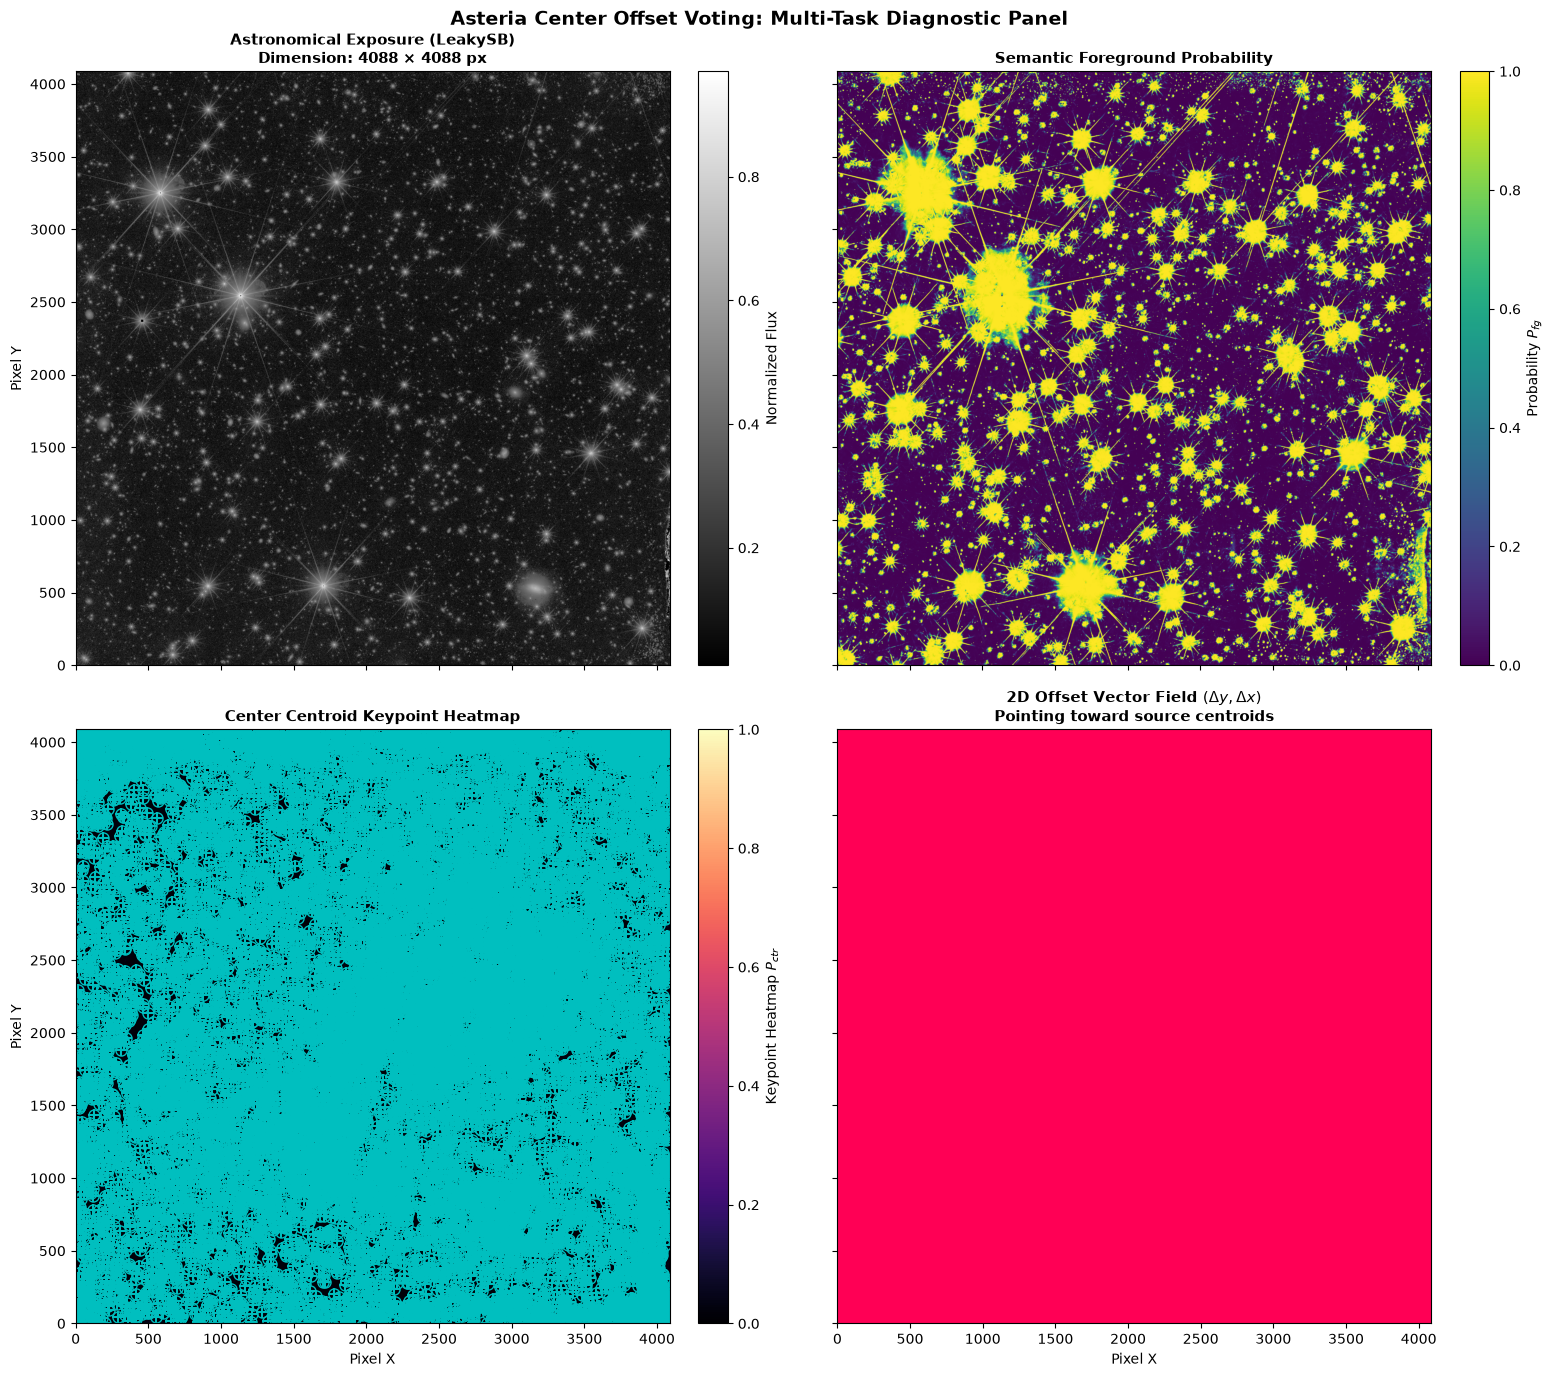

In [7]:
peaks = extract_center_peaks(pred_center, threshold=0.10, min_distance=3)
print(f"Extracted {len(peaks)} candidate center centroid peaks via peak NMS")

fig = plot_center_offset_multipanel(
    stretched=stretched_img,
    pred_semantic=pred_semantic,
    pred_center=pred_center,
    pred_offset=pred_offset,
    peaks=peaks,
    quiver_step=8,
    title="Asteria Center Offset Voting: Multi-Task Diagnostic Panel",
)
plt.show()

---
## 6. Two-Panel Comparison: Stretched Image vs. Model Segmented Mask

Using `plot_center_offset_segmentation()`, we render a high-contrast side-by-side comparison directly from the model outcomes:
1. **Left Panel**: The photometrically stretched astronomical exposure (normalized LeakySB flux).
2. **Right Panel**: The segmented mask obtained directly from the model predictions (`pred_semantic`, `pred_center`, `pred_offset`), displaying deblended source instances or segmented foreground emission.

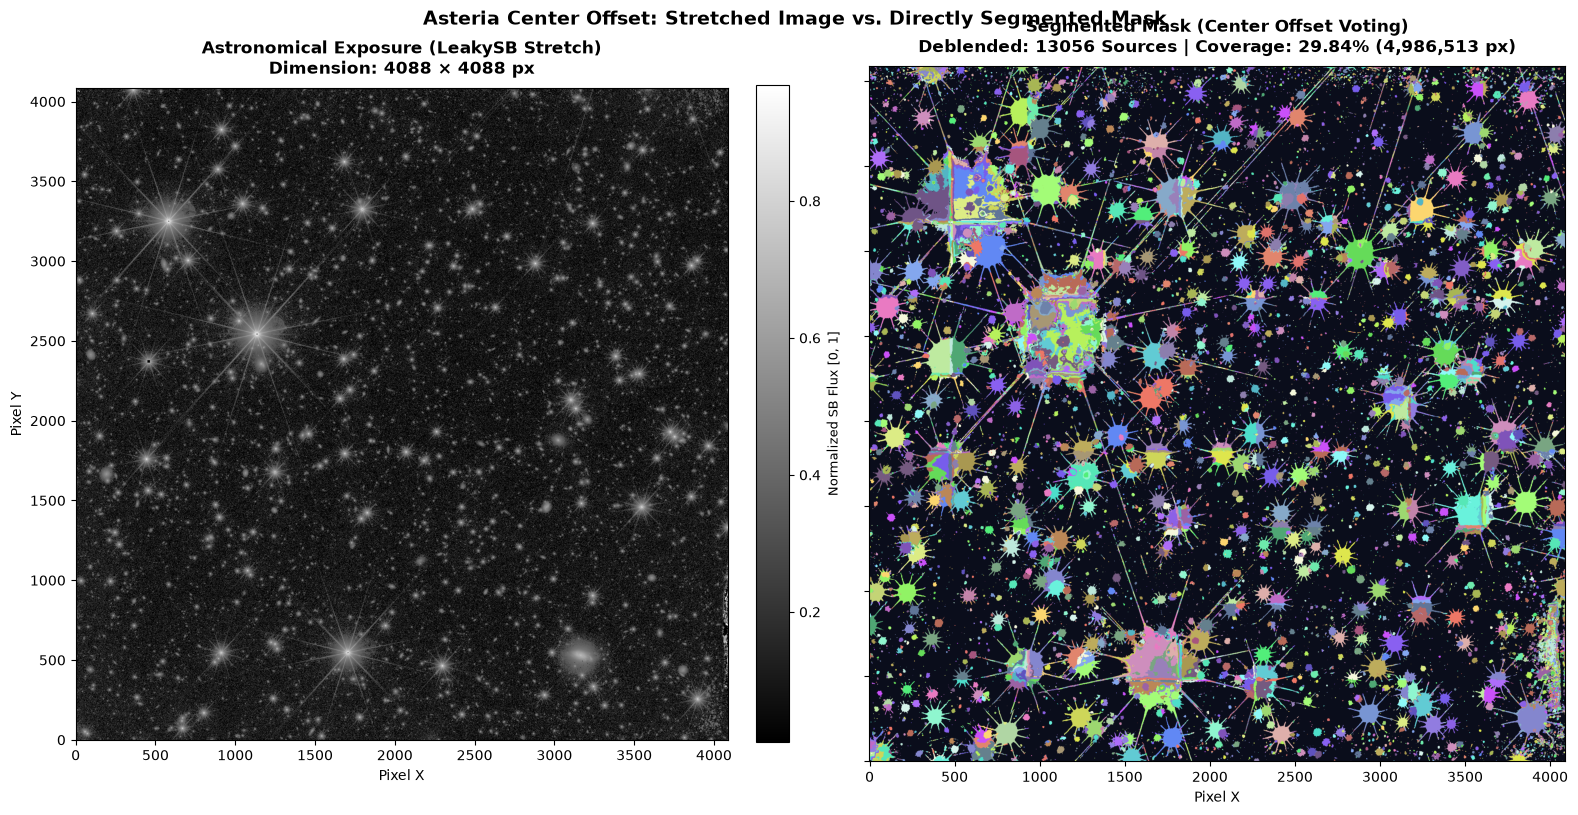

In [8]:
# Render side-by-side comparison directly using the outcomes of the model
fig_two_panel = asteria.plot_center_offset_segmentation(
    stretched=stretched_img,
    pred_semantic=pred_semantic,
    pred_center=pred_center,
    pred_offset=pred_offset,
    fg_thresh=0.20,
    center_thresh=0.10,
    title="Asteria Center Offset: Stretched Image vs. Directly Segmented Mask",
)
plt.show()

---
## 7. Colinear Ray-Aligned Offset Deblending (`segment_instances`)

By evaluating $(y^*, x^*) = (y + \Delta y, x + \Delta x)$, foreground pixels cast continuous geometric votes toward candidate center peaks. The **colinear angular filter** enforces that extended features (diffraction spikes, tidal arms) only cluster with centroids that align with their spatial direction vectors, preventing bleed into intersecting galaxies.

In [ ]:
results = segmentor.segment_instances(
    image=scene_path,
    stretch_type="leakysb",
    fg_thresh=0.20,
    center_thresh=0.10,
    colinear_thresh=0.70,
    max_vote_dist=64.0,
    min_area=4,
    verbose=True,
)

print(f"Extracted {len(results.masks)} discrete source instances")
print(f"Segmentation Map Shape: {results.segmap.shape}")

---
## 8. Instance Overlay Visualization

We overlay the extracted instance masks and centroids atop the LeakySB astronomical exposure using `plot_instance_overlay()`.

In [ ]:
fig_overlay = plot_instance_overlay(
    stretched=stretched_img,
    masks=results.masks,
    centroids=results.centroids,
    title=f"Asteria Center Offset Voting: Deblended Instances ({len(results.masks)} sources)",
)
plt.show()

---
## 9. Exporting Astronomical Catalogs and FITS Segmentation Masks

Finally, we export the 2D integer segmentation map (compatible with SourceExtractor / SExtractor / Photutils) to FITS format, and display the source catalog.

In [ ]:
out_fits = Path("center_offset_segmap.fits")
fits.PrimaryHDU(data=results.segmap.astype(np.int32)).writeto(str(out_fits), overwrite=True)
print(f"Exported FITS 2D instance segmentation map to: {out_fits.resolve()}")

if len(results.masks) > 0:
    print(f"\n{'ID':>4} | {'Centroid (X, Y)':>18} | {'BBox [X0, Y0, X1, Y1]':>24} | {'Area (px)':>9} | {'Mean Prob':>9}")
    print("-" * 78)
    for i in range(min(15, len(results.masks))):
        cx, cy = results.centroids[i]
        bbox = [round(b, 1) for b in results.boxes[i]]
        print(f"{i+1:>4} | ({cx:7.2f}, {cy:7.2f}) | {str(bbox):>24} | {results.areas[i]:>9} | {results.scores[i]:>9.3f}")
else:
    print("No instances passed current threshold filters.")